# E-Commerce Review Intelligence — End-to-End Walkthrough

**Interview notebook:** data quality → exploratory analysis → weak-label sentiment modeling → out-of-time evaluation → candidate issue analytics → reviewer signals.

This walkthrough uses the prepared Amazon Reviews 2023 **All_Beauty** sample and the model artifacts produced by the project pipeline. It does not silently download the raw 326 MB dataset or retrain the full model when opened. From the repository root, run `python -m src.prepare_review_intelligence` to prepare data and `python -m src.train_review_sentiment` to train and score it. Then open this notebook with the project `.venv` kernel and choose **Run All**.

**Scope and honesty:** sentiment targets are derived from star ratings (1–2 negative, 3 neutral, 4–5 positive), so this is weak supervision—not an independent human sentiment benchmark. Issue tags are transparent regex candidates, not verified defects. No 91% issue-tag precision claim is supported until the human audit is completed.

**Current saved run:** 399,596 valid reviews, 87,139 products, 373,031 reviewers. The saved model reports 85.12% accuracy / 0.6997 macro-F1 on the chronological held-out test against rating-derived labels. The dashboard deliberately leaves training-period sentiment unscored.

In [1]:
from pathlib import Path
import json

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

from src.issue_tagging import ISSUE_PATTERNS, TAG_DESCRIPTIONS, has_issue_tags, normalize_tags, tag_review
from src.train_review_sentiment import (
    LABELS,
    METRICS_PATH,
    MODEL_PATH,
    SCORED_DATA_PATH,
    build_pipeline,
    rating_sentiment,
    remove_duplicate_review_text,
    train_and_score,
)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src').is_dir():
    PROJECT_ROOT = next(
        (parent for parent in Path.cwd().parents if (parent / 'src').is_dir()),
        PROJECT_ROOT,
    )
DATA_PATH = PROJECT_ROOT / 'data' / 'review_intelligence.parquet'
STATS_PATH = PROJECT_ROOT / 'data' / 'review_intelligence_stats.json'
SCORED_PATH = PROJECT_ROOT / 'data' / 'review_intelligence_scored.parquet'
ANNOTATION_PATH = PROJECT_ROOT / 'data' / 'issue_tag_annotations.csv'

required_files = [DATA_PATH, STATS_PATH, SCORED_PATH, METRICS_PATH, MODEL_PATH]
missing_files = [str(path) for path in required_files if not path.is_file()]
if missing_files:
    raise FileNotFoundError(
        'Project artifacts are missing: ' + ', '.join(missing_files)
        + '. Run the prepare and train commands shown above first.'
    )

stats = json.loads(STATS_PATH.read_text(encoding='utf-8'))
reviews = pd.read_parquet(SCORED_PATH)
reviews['review_time'] = pd.to_datetime(reviews['review_time'], utc=True, errors='coerce')
print(f'Loaded {len(reviews):,} scored review records from {SCORED_PATH.name}.')
print(f'Random sampling seed: {stats["random_sample_seed"]}; invalid sampled records dropped: {stats["dropped_invalid_rows"]:,}.')

Loaded 399,596 scored review records from review_intelligence_scored.parquet.
Random sampling seed: 42; invalid sampled records dropped: 404.


## 1. Data preparation and quality checks

The preparation script takes a deterministic random sample of source rows, normalizes IDs, timestamps, ratings and text, drops records missing required fields, and writes review-level Parquet in batches. The sample is processed locally; raw review text is not committed to the repository. The checks below make those assumptions observable instead of treating a successful file load as proof of clean data.

The prepared sample has a unique source-line `review_id`. Exact normalized title/body duplicates are handled separately before the temporal model split; this avoids the same copied text appearing in both train and evaluation periods.

In [2]:
core_columns = ['review_id', 'product_id', 'reviewer_id', 'rating', 'review_time', 'title', 'review_text']
quality_profile = pd.Series({
    'Source rows in category': stats['source_rows'],
    'Valid sampled reviews': len(reviews),
    'Invalid sampled rows dropped': stats['dropped_invalid_rows'],
    'Unique products': reviews['product_id'].nunique(),
    'Unique reviewers': reviews['reviewer_id'].nunique(),
    'Duplicate review IDs': int(reviews['review_id'].duplicated().sum()),
    'Missing core values': int(reviews[core_columns].isna().sum().sum()),
    'Empty review bodies': int(reviews['review_text'].fillna('').astype(str).str.strip().eq('').sum()),
    'Ratings outside 1–5': int((~reviews['rating'].between(1, 5)).sum()),
    'First review date (UTC)': str(reviews['review_time'].min()),
    'Last review date (UTC)': str(reviews['review_time'].max()),
})
display(quality_profile.to_frame('Observed value'))
display(reviews[['rating', 'review_time']].head(5))

text_lengths = reviews['review_text'].fillna('').astype(str).str.len()
display(text_lengths.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).rename('Characters per review').to_frame())

,Observed value
Source rows in category,701528
Valid sampled reviews,399596
Invalid sampled rows dropped,404
Unique products,87139
Unique reviewers,373031
Duplicate review IDs,0
Missing core values,0
Empty review bodies,0
Ratings outside 1–5,0
First review date (UTC),2000-11-01 04:24:18+00:00


,rating,review_time
0,5.0,2020-05-05 14:08:48+00:00
1,5.0,2020-12-30 10:02:43+00:00
2,4.0,2020-08-27 22:30:08+00:00
3,5.0,2021-09-17 13:31:59+00:00
4,5.0,2021-07-27 13:04:04+00:00


,Characters per review
count,399596.000000
mean,173.043989
std,246.089614
min,1.000000
50%,102.000000
90%,386.000000
95%,559.000000
99%,1143.000000
max,14989.000000


## 2. Dataset characteristics and exploratory analysis

The category is strongly skewed toward five-star reviews. This matters twice: a majority-class baseline is necessary, and macro-F1 should be read alongside per-class recall/F1 rather than relying on accuracy alone. The monthly volume plot shows the time coverage of this random sample; it is not a causal or seasonally adjusted trend.

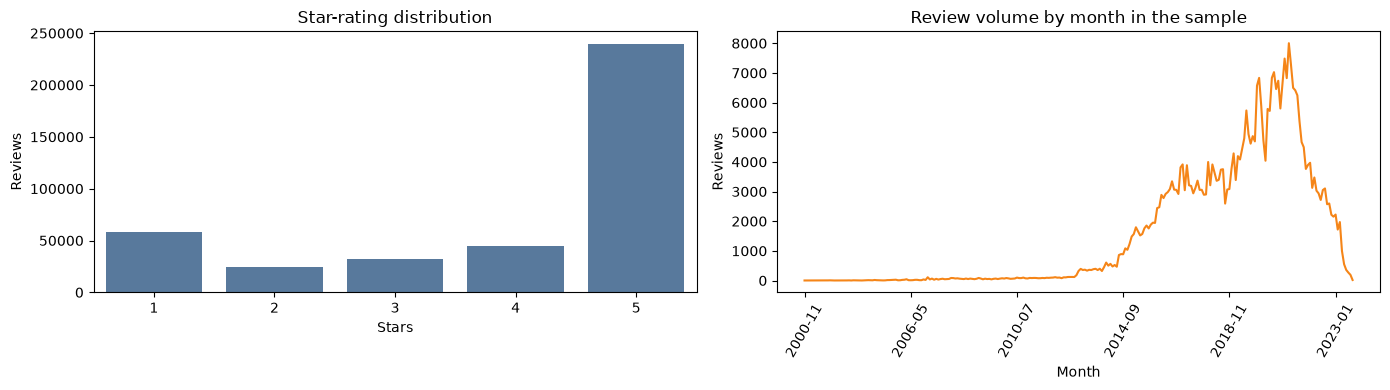

,Reviews
Stars,
1.0,58191
2.0,24512
3.0,32092
4.0,45038
5.0,239763


In [3]:
rating_counts = reviews['rating'].value_counts().sort_index()
month_key = reviews['review_time'].dt.tz_localize(None).dt.to_period('M').astype(str)
monthly_volume = month_key.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(x=rating_counts.index.astype(int), y=rating_counts.values, ax=axes[0], color='#4C78A8')
axes[0].set(title='Star-rating distribution', xlabel='Stars', ylabel='Reviews')
axes[0].ticklabel_format(axis='y', style='plain')
monthly_volume.plot(ax=axes[1], color='#F58518', linewidth=1.5)
axes[1].set(title='Review volume by month in the sample', xlabel='Month', ylabel='Reviews')
axes[1].tick_params(axis='x', labelrotation=60)
plt.tight_layout()
plt.show()

display(rating_counts.rename_axis('Stars').rename('Reviews').to_frame())

## 3. Label construction and imbalance

There is no human sentiment label in the public category file, so the model uses star ratings as a **weak target**: 1–2 → negative, 3 → neutral, 4–5 → positive. That target is noisy: star rating and wording can disagree, and neutral is particularly difficult. The label mapping is kept explicit so the interview discussion does not confuse rating prediction with human sentiment ground truth.

In [4]:
weak_labels = rating_sentiment(reviews['rating'])
sentiment_names = {0: 'Negative', 1: 'Neutral', 2: 'Positive'}
label_counts = weak_labels.value_counts().sort_index().rename(index=sentiment_names)
label_summary = pd.DataFrame({
    'Reviews': label_counts,
    'Share': label_counts / label_counts.sum(),
})
display(label_summary.style.format({'Reviews': '{:,.0f}', 'Share': '{:.1%}'}))
print('Weak-label mapping: 1-2 stars = Negative; 3 = Neutral; 4-5 = Positive.')

,Reviews,Share
rating,,
Negative,"82,703",20.7%
Neutral,"32,092",8.0%
Positive,"284,801",71.3%


Weak-label mapping: 1-2 stars = Negative; 3 = Neutral; 4-5 = Positive.


## 4. Duplicate handling and chronological evaluation design

Normalized exact title/body duplicates are removed before splitting, keeping the earliest timestamp. The timeline is then divided into 60% train, 10% hyperparameter-selection validation, 10% independent out-of-time validation, and 20% held-out test. The first validation interval selects regularization strength; the separate next interval provides out-of-time dashboard predictions; the test period is reserved for final evaluation. This prevents copied review text and future reviews from leaking into earlier evaluation data.

In [5]:
model_frame = reviews.dropna(subset=['rating', 'review_time', 'review_text']).copy()
model_frame['label'] = rating_sentiment(model_frame['rating']).astype(int)
model_frame['model_text'] = (
    model_frame['title'].fillna('').astype(str).str.strip()
    + '. '
    + model_frame['review_text'].fillna('').astype(str).str.strip()
).str.strip()
model_frame = model_frame.loc[model_frame['model_text'].str.len().gt(0)]
deduplicated, duplicate_text_rows = remove_duplicate_review_text(model_frame)

cutoffs = [0, 0.6, 0.7, 0.8, 1.0]
split_names = ['Train', 'Tuning validation', 'Out-of-time validation', 'Held-out test']
split_rows = []
for split_name, lower, upper in zip(split_names, cutoffs[:-1], cutoffs[1:]):
    start = int(len(deduplicated) * lower)
    stop = int(len(deduplicated) * upper)
    split = deduplicated.iloc[start:stop]
    split_rows.append({
        'Split': split_name,
        'Rows': len(split),
        'First date': split['review_time'].min(),
        'Last date': split['review_time'].max(),
        'Negative': int(split['label'].eq(0).sum()),
        'Neutral': int(split['label'].eq(1).sum()),
        'Positive': int(split['label'].eq(2).sum()),
    })
print(f'Normalized exact-text duplicate rows removed before splitting: {duplicate_text_rows:,}.')
print(f'Rows remaining for the chronological model experiment: {len(deduplicated):,}.')
display(pd.DataFrame(split_rows).set_index('Split').style.format({'Rows': '{:,.0f}', 'Negative': '{:,.0f}', 'Neutral': '{:,.0f}', 'Positive': '{:,.0f}'}))

Normalized exact-text duplicate rows removed before splitting: 15,586.
Rows remaining for the chronological model experiment: 384,010.


,Rows,First date,Last date,Negative,Neutral,Positive
Split,,,,,,
Train,"230,406",2000-11-01 04:24:18+00:00,2020-06-11 17:57:10+00:00,"43,748","18,891","167,767"
Tuning validation,"38,401",2020-06-11 17:57:15+00:00,2020-12-15 00:58:37+00:00,"8,017","3,069","27,315"
Out-of-time validation,"38,401",2020-12-15 01:05:13+00:00,2021-05-29 23:11:08+00:00,"9,071","3,130","26,200"
Held-out test,"76,802",2021-05-29 23:34:29+00:00,2023-09-09 00:39:36+00:00,"20,707","6,402","49,693"


## 5. Model and training

**Text representation:** TF-IDF word unigrams and bigrams, lowercased with Unicode accents stripped, capped at 100,000 features. Bigrams capture short phrases such as *not effective* while TF-IDF downweights very common terms.

**Classifier:** `SGDClassifier(loss='log_loss', class_weight='balanced')`. Log loss gives class probabilities; balanced class weights counter rating imbalance during fitting. The tuning interval compares two regularization strengths by macro-F1 (accuracy breaks ties). The selected configuration is refit on the first 80% before test scoring.

The cell below uses the already saved run by default so **Run All is quick and presentation-safe**. Set `RUN_FULL_TRAINING = True` to retrain through the canonical production function; that operation rewrites model and scored-data artifacts and takes several minutes.

In [6]:
RUN_FULL_TRAINING = False
if RUN_FULL_TRAINING:
    training_result = train_and_score(data_path=DATA_PATH, scored_data_path=SCORED_PATH)
    print('Full chronological training and scoring completed.')
else:
    print('Using the saved training run. Set RUN_FULL_TRAINING=True to retrain.')

model_results = json.loads(METRICS_PATH.read_text(encoding='utf-8'))
selected_alpha = model_results['validation_hyperparameter_candidates']['selected_alpha']
pipeline_template = build_pipeline(alpha=selected_alpha)
print(f'Selected SGD regularization alpha: {selected_alpha:g}')
print(f'Model steps: {list(pipeline_template.named_steps)}')
print(f'Saved model: {MODEL_PATH.relative_to(PROJECT_ROOT)}')
display(pd.DataFrame.from_dict(
    model_results['validation_hyperparameter_candidates']['metrics_by_alpha'],
    orient='index',
).rename_axis('SGD alpha'))

Using the saved training run. Set RUN_FULL_TRAINING=True to retrain.
Selected SGD regularization alpha: 0.0001
Model steps: ['tfidf', 'classifier']
Saved model: models\review_sentiment_pipeline.joblib


,accuracy,macro_f1,confusion_matrix_negative_neutral_positive,classification_report
SGD alpha,,,,
0.0001,0.865056,0.700257,"[[6314, 609, 1094], [972, 1035, 1062], [560, 8...","{'negative': {'precision': 0.8047412694366556,..."
0.001,0.784511,0.479614,"[[2863, 50, 5104], [280, 94, 2695], [93, 53, 2...","{'negative': {'precision': 0.884734239802225, ..."


## 6. Held-out results and prediction coverage

Accuracy answers how often the weak rating-derived class was matched; macro-F1 gives each class equal weight. Compare both to the majority baseline and inspect neutral-class performance. The dashboard stores sentiment predictions only for the independent validation and test periods—not for rows the final model trained on. All sampled reviews still contribute to rating, volume, issue-candidate, and reviewer analyses.

,Accuracy,Macro-F1,Neutral F1
TF-IDF + balanced SGD,0.851,0.700,0.358
Majority baseline,0.647,0.262,0.000


Held-out test rows: 76,802; test target is rating-derived, not human annotated.
Per-class precision, recall and F1:


,precision,recall,f1-score,support
negative,0.838310,0.799971,0.818692,20707.0
neutral,0.387436,0.333333,0.358354,6402.0
positive,0.905693,0.939247,0.922165,49693.0


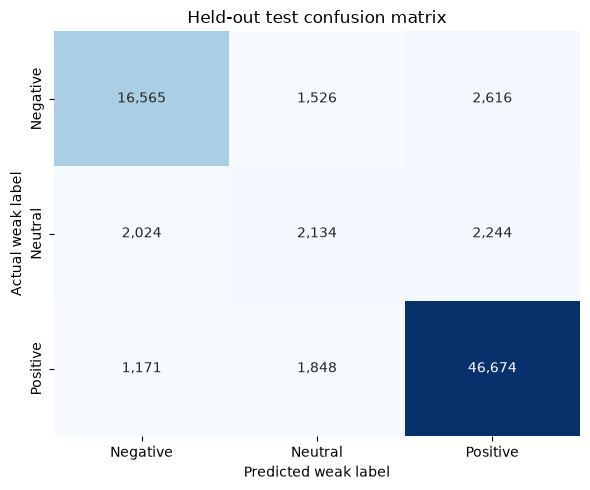

Out-of-time dashboard sentiment predictions: 115,203 reviews across 37,068 products.
Validation predictions: 38,401; held-out test predictions: 76,802.
Neutral F1 is 0.358; treat this as a clear limitation, not a result to hide.


In [7]:
test_metrics = model_results['held_out_test_metrics']
baseline_metrics = model_results['majority_class_baseline_test_metrics']
metric_table = pd.DataFrame({
    'TF-IDF + balanced SGD': {
        'Accuracy': test_metrics['accuracy'],
        'Macro-F1': test_metrics['macro_f1'],
        'Neutral F1': test_metrics['classification_report']['neutral']['f1-score'],
    },
    'Majority baseline': {
        'Accuracy': baseline_metrics['accuracy'],
        'Macro-F1': baseline_metrics['macro_f1'],
        'Neutral F1': baseline_metrics['classification_report']['neutral']['f1-score'],
    },
}).T
display(metric_table.style.format('{:.3f}'))
print(f"Held-out test rows: {model_results['test_rows']:,}; test target is rating-derived, not human annotated.")
print('Per-class precision, recall and F1:')
class_report = pd.DataFrame(test_metrics['classification_report']).T
display(class_report.loc[['negative', 'neutral', 'positive'], ['precision', 'recall', 'f1-score', 'support']])

confusion = test_metrics['confusion_matrix_negative_neutral_positive']
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(confusion, annot=True, fmt=',d', cmap='Blues', cbar=False,
            xticklabels=['Negative', 'Neutral', 'Positive'],
            yticklabels=['Negative', 'Neutral', 'Positive'], ax=ax)
ax.set(title='Held-out test confusion matrix', xlabel='Predicted weak label', ylabel='Actual weak label')
plt.tight_layout()
plt.show()

prediction_counts = model_results['out_of_time_prediction_counts']
oos_mask = reviews['sentiment_is_out_of_sample'].astype(bool)
oos_products = reviews.loc[oos_mask, 'product_id'].nunique()
print(f"Out-of-time dashboard sentiment predictions: {prediction_counts['total']:,} reviews across {oos_products:,} products.")
print(f"Validation predictions: {prediction_counts['validation']:,}; held-out test predictions: {prediction_counts['test']:,}.")
print(f"Neutral F1 is {test_metrics['classification_report']['neutral']['f1-score']:.3f}; treat this as a clear limitation, not a result to hide.")

## 7. Saved-model prediction demo

The example below uses an actual held-out test-period review, so it is scored by the final model that was trained before that review's time window. The “reference” column is still the star-rating-derived weak label; agreement does not prove human sentiment correctness.

In [8]:
saved_model = joblib.load(MODEL_PATH)
test_examples = reviews.loc[reviews['sentiment_prediction_split'].eq('test_oos')]
if test_examples.empty:
    raise ValueError('No held-out test predictions are present. Retrain and rescore the prepared dataset.')
example = test_examples.sort_values(['review_time', 'review_id']).iloc[0]
example_text = f"{example['title']}. {example['review_text']}".strip()
predicted_class = int(saved_model.predict([example_text])[0])
class_probabilities = saved_model.predict_proba([example_text])[0]
probability_by_class = {int(label): float(probability) for label, probability in zip(saved_model.classes_, class_probabilities)}
weak_label = int(rating_sentiment(pd.Series([example['rating']])).iloc[0])
prediction_demo = pd.DataFrame([{
    'Review ID': int(example['review_id']),
    'Star rating': float(example['rating']),
    'Rating-derived reference': LABELS[weak_label],
    'Model prediction': LABELS[predicted_class],
    'Predicted class probability': probability_by_class[predicted_class],
    'Time split': example['sentiment_prediction_split'],
}])
display(prediction_demo.style.format({'Predicted class probability': '{:.1%}'}))

,Review ID,Star rating,Rating-derived reference,Model prediction,Predicted class probability,Time split
0,70299,5.000000,Positive,Positive,71.8%,test_oos


## 8. Candidate issue tagging and human-audit status

The issue taxonomy contains 32 readable regex rules. A match is a **candidate signal** that helps an analyst find text—not a validated issue classification. Repeated counts across products support prioritization, not proof of a defect. The separate audit samples both tagged and untagged reviews, oversamples candidates, and applies population weights. Precision stays unreported until every sampled primary label is complete.

Synthetic rule demo: ['leakage', 'strong_fragrance']


32 rule-defined tags; 32 appear in this sample.
32 candidate categories meet the dashboard threshold: at least 25 reviews across at least 3 products.
64,216 reviews have at least one candidate tag; do not describe them as human-validated issues.


,Description,Reviews,Products
issue_tags,,,
dryness,Product caused or worsened dryness,17125,8714
poor_value,Price or value complaint,8391,6026
rash_or_irritation,"Skin irritation, rash, itching, or burning",7033,4074
ineffective,Product did not produce the expected effect,5018,3175
poor_quality,General quality or durability complaint,4925,3457
broken_packaging,Broken product container or package,4650,3137
sticky_texture,Sticky or tacky texture,4128,2983
greasy_texture,Greasy or oily residue,3586,2093
leakage,Product leaked or spilled,2355,1423


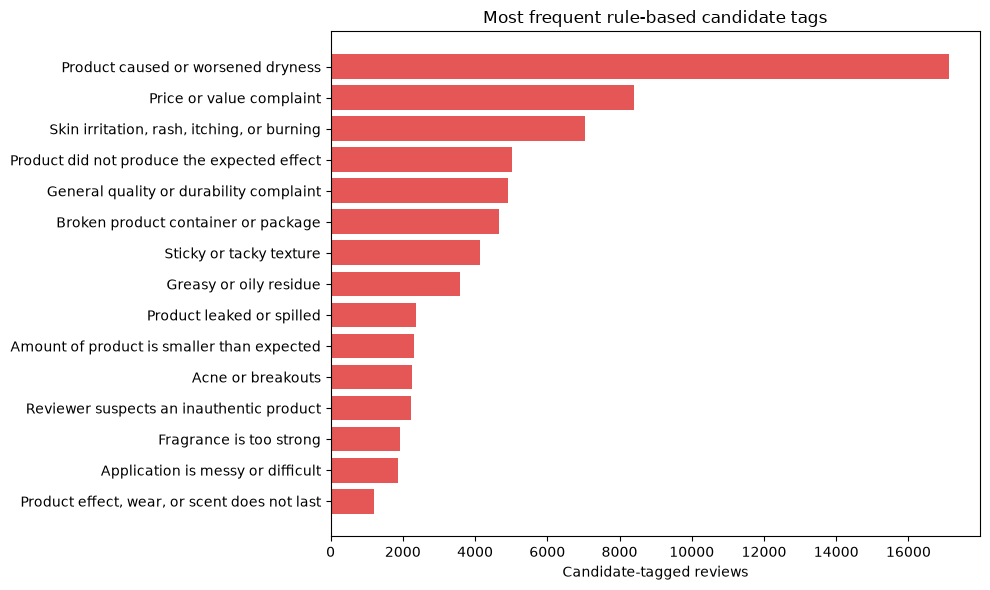

Human audit progress: 0 of 400 primary labels completed.
Precision is not yet measured. Complete the blind annotation workflow in the Streamlit Issue Tag Audit page.


In [9]:
synthetic_example = 'The bottle leaked during shipping and the scent was too strong.'
print('Synthetic rule demo:', tag_review(synthetic_example))
tagged_reviews = reviews.loc[reviews['issue_tags'].map(has_issue_tags)].copy()
tagged_reviews['issue_tags'] = tagged_reviews['issue_tags'].map(normalize_tags)
issue_rows = tagged_reviews.explode('issue_tags').dropna(subset=['issue_tags'])
candidate_counts = issue_rows.groupby('issue_tags').agg(
    Reviews=('review_id', 'nunique'),
    Products=('product_id', 'nunique'),
).sort_values('Reviews', ascending=False)
candidate_counts['Description'] = candidate_counts.index.map(TAG_DESCRIPTIONS)
recurring_candidates = candidate_counts.loc[
    candidate_counts['Reviews'].ge(25) & candidate_counts['Products'].ge(3)
]
print(f'{len(ISSUE_PATTERNS)} rule-defined tags; {len(candidate_counts)} appear in this sample.')
print(f'{len(recurring_candidates)} candidate categories meet the dashboard threshold: at least 25 reviews across at least 3 products.')
print(f'{len(tagged_reviews):,} reviews have at least one candidate tag; do not describe them as human-validated issues.')
display(candidate_counts[['Description', 'Reviews', 'Products']].head(15))

fig, ax = plt.subplots(figsize=(10, 6))
top_candidates = candidate_counts.head(15).sort_values('Reviews')
ax.barh(top_candidates['Description'], top_candidates['Reviews'], color='#E45756')
ax.set(title='Most frequent rule-based candidate tags', xlabel='Candidate-tagged reviews', ylabel='')
plt.tight_layout()
plt.show()

if ANNOTATION_PATH.is_file():
    audit = pd.read_csv(ANNOTATION_PATH, keep_default_na=False)
    primary_labels = audit['human_tags'].astype(str).str.strip().ne('').sum()
    print(f'Human audit progress: {primary_labels:,} of {len(audit):,} primary labels completed.')
    if primary_labels < len(audit):
        print('Precision is not yet measured. Complete the blind annotation workflow in the Streamlit Issue Tag Audit page.')
else:
    print('No audit sample exists yet. Create one from the Streamlit Issue Tag Audit page.')

## 9. Reviewer and temporal signals

The dashboard derives reviewer volume, activity span, reviews per active month, negative share from out-of-time predictions, and the share of text reused by three or more reviewers. These are review-pattern investigation signals only. The calculations do not identify a person, establish coordination, or prove fraudulent behavior.

In [10]:
reviewer_count = reviews.groupby('reviewer_id').size().rename('review_count')
reviewer_dates = reviews.groupby('reviewer_id')['review_time'].agg(first_review='min', last_review='max')
review_month = reviews['review_time'].dt.tz_localize(None).dt.to_period('M').astype(str)
active_months = reviews.assign(review_month=review_month).groupby('reviewer_id')['review_month'].nunique().rename('active_months')
normalized_text = reviews['review_text'].fillna('').astype(str).str.casefold().str.replace(r'\s+', ' ', regex=True).str.strip()
reviewers_per_text = pd.DataFrame({'reviewer_id': reviews['reviewer_id'], 'text_key': normalized_text}).groupby('text_key')['reviewer_id'].nunique()
reused_share = reviews.assign(reused_text=normalized_text.map(reviewers_per_text).ge(3)).groupby('reviewer_id')['reused_text'].mean().rename('reused_text_share')
out_of_time_reviews = reviews.loc[reviews['sentiment_is_out_of_sample'].astype(bool)]
negative_share = out_of_time_reviews.assign(is_negative=out_of_time_reviews['sentiment_label'].eq('Negative')).groupby('reviewer_id')['is_negative'].mean().rename('negative_share_oos')
reviewer_profile = pd.concat([reviewer_count, reviewer_dates, active_months, reused_share, negative_share], axis=1)
reviewer_profile['reviews_per_active_month'] = reviewer_profile['review_count'] / reviewer_profile['active_months'].clip(lower=1)
reviewer_profile['high_volume_signal'] = reviewer_profile['review_count'].ge(reviewer_profile['review_count'].quantile(0.99))
display(reviewer_profile.sort_values('review_count', ascending=False).head(10).reset_index(drop=True))
print('Negative share is NaN when a reviewer has no out-of-time sentiment predictions; unscored training-period reviews are not counted as non-negative.')

,review_count,first_review,last_review,active_months,reused_text_share,negative_share_oos,reviews_per_active_month,high_volume_signal
0,102,2015-03-08 00:36:25+00:00,2022-01-04 02:17:13+00:00,35,0.0,0.058824,2.914286,True
1,77,2019-12-04 14:46:25+00:00,2022-03-01 18:07:57+00:00,20,0.0,0.0,3.850000,True
2,56,2019-08-10 17:17:24+00:00,2022-10-19 03:02:12+00:00,23,0.0,0.02439,2.434783,True
3,55,2020-07-28 23:16:24+00:00,2021-01-28 19:35:38+00:00,7,0.0,0.0,7.857143,True
4,52,2020-09-16 02:37:45+00:00,2023-03-14 16:28:21+00:00,23,0.0,0.040816,2.260870,True
5,50,2020-09-07 02:16:01+00:00,2023-04-24 11:36:35+00:00,22,0.0,0.210526,2.272727,True
6,48,2020-03-11 00:03:35+00:00,2021-07-25 21:37:59+00:00,11,0.0,0.142857,4.363636,True
7,42,2021-07-29 20:49:17+00:00,2022-11-21 23:08:31+00:00,14,0.0,0.047619,3.000000,True
8,40,2014-10-12 01:46:09+00:00,2022-04-21 21:33:07+00:00,22,0.0,0.0,1.818182,True
9,39,2018-05-02 01:44:18+00:00,2022-10-20 12:23:08+00:00,20,0.0,0.066667,1.950000,True


Negative share is NaN when a reviewer has no out-of-time sentiment predictions; unscored training-period reviews are not counted as non-negative.


## 10. Interview-ready summary and limitations

**A concise explanation:** “I prepared a reproducible 399K-review All_Beauty sample, checked data quality and product/reviewer coverage, and trained a TF-IDF word uni-/bigram classifier using rating-derived three-class weak labels. I removed 15,586 normalized exact-text duplicates before a chronological 60/10/10/20 split, selected regularization on a validation window, and reserved later periods for out-of-time predictions and final testing. The held-out model reached 85.12% accuracy and 0.6997 macro-F1 versus a 64.70% / 0.2619 majority baseline; neutral F1 is only 0.358, so I state the weak-label caveat. I also built 32 interpretable candidate issue rules, reviewer/time signals, 10+ dashboard views, and a weighted human-audit workflow. Issue-tag precision is not claimed yet because the audit labels are unfinished.”

**What not to overclaim:** the model predicts rating-derived labels, not human sentiment; regex tags are not validated product defects; reviewer flags are not fraud findings; and the 91% precision target remains unverified. The next defensible step is to finish the blinded primary annotation, double-code a subset, report population-weighted precision with uncertainty, and revise rules based on the observed false positives/negatives.

**Reproducibility:** the production logic lives in `src/prepare_review_intelligence.py`, `src/train_review_sentiment.py`, `src/issue_tagging.py`, and `src/issue_audit.py`; the notebook calls those same functions rather than maintaining a second implementation. The raw dataset and generated artifacts are local and ignored by Git.